# ibmq_oslo

In [1]:
# ===== 0. Local-or-IBM setup =====
# This makes notebooks run on IBM if available; otherwise uses local Aer.
import warnings
warnings.filterwarnings("ignore")
import numpy as np

use_ibm = False
try:
    from qiskit_ibm_runtime import QiskitRuntimeService, Sampler as IBMSampler
    try:
        service = QiskitRuntimeService()
        backend = service.backend("ibmq_qasm_simulator")
        sampler = IBMSampler(session=service)
        use_ibm = True
        print("Using IBM runtime:", backend.name())
    except Exception:
        use_ibm = False
except Exception:
    use_ibm = False

if not use_ibm:
    try:
        from qiskit_aer import AerSimulator
        from qiskit_aer.primitives import Sampler as AerSampler
        simulator = AerSimulator()
        sampler = AerSampler()
        backend = simulator
        print("Using local AerSimulator / AerSampler")
    except Exception as e:
        from qiskit import Aer
        backend = Aer.get_backend("aer_simulator")
        sampler = None
        print("Using qiskit.Aer.get_backend('aer_simulator') (sampler not available)")

# Standard imports
from qiskit import QuantumCircuit
from qiskit.utils import algorithm_globals
from qiskit.visualization import *
import matplotlib.pyplot as plt
import math
import cplex
from cplex.exceptions import CplexError


Using local AerSimulator / AerSampler


In [2]:
# ===== 1. Initialize problem parameters =====
n = 4  # number of nodes (including depot)
K = 2  # number of vehicles

class Initializer:
    def __init__(self, n):
        self.n = n

    def generate_instance(self):
        np.random.seed(1543)
        xc = (np.random.rand(self.n) - 0.5) * 10
        yc = (np.random.rand(self.n) - 0.5) * 10
        instance = np.zeros([self.n, self.n])
        for i in range(self.n):
            for j in range(i+1, self.n):
                instance[i,j] = (xc[i]-xc[j])**2 + (yc[i]-yc[j])**2
                instance[j,i] = instance[i,j]
        return xc, yc, instance

initializer = Initializer(n)
xc, yc, instance = initializer.generate_instance()


In [3]:
# ===== 2. Classical optimizer using CPLEX =====
class ClassicalOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def compute_allowed_combinations(self):
        f = math.factorial
        return f(self.n) / f(self.K) / f(self.n - self.K)

    def cplex_solution(self):
        instance, n, K = self.instance, self.n, self.K
        my_obj = list(instance.reshape(1,n**2)[0]) + [0.0]*(n-1)
        my_ub = [1]*(n**2 + n -1)
        my_lb = [0]*(n**2) + [0.1]*(n-1)
        my_ctype = "".join(["I"]*n**2 + ["C"]*(n-1))
        my_rhs = 2*([K] + [1]*(n-1)) + [1-0.1]*((n-1)**2-(n-1)) + [0]*n
        my_sense = "".join(["E"]*(2*n) + ["L"]*((n-1)**2-(n-1)) + ["E"]*n)

        try:
            my_prob = cplex.Cplex()
            self.populatebyrow(my_prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs)
            my_prob.solve()
        except CplexError as exc:
            print("CPLEX error:", exc)
            return None, None

        x = np.array(my_prob.solution.get_values())
        cost = my_prob.solution.get_objective_value()
        return x, cost

    def populatebyrow(self, prob, obj, ub, lb, ctype, sense, rhs):
        n = self.n
        prob.objective.set_sense(prob.objective.sense.minimize)
        prob.variables.add(obj=obj, lb=lb, ub=ub, types=ctype)
        prob.set_log_stream(None)
        prob.set_error_stream(None)
        prob.set_warning_stream(None)
        prob.set_results_stream(None)

        rows = []
        for i in range(n):
            rows.append([[j for j in range(i*n, i*n + n)], [1]*n])
        for i in range(n):
            rows.append([[j for j in range(i, n**2, n)], [1]*n])
        for i in range(n):
            for j in range(n):
                if i!=j and i*j>0:
                    rows.append([[i + j*n, n**2+i-1, n**2+j-1],[1,1,-1]])
        for i in range(n):
            rows.append([[i*(n+1)], [1]])
        prob.linear_constraints.add(lin_expr=rows, senses=sense, rhs=rhs)

classical_optimizer = ClassicalOptimizer(instance, n, K)
print("Feasible solutions count:", classical_optimizer.compute_allowed_combinations())
x, classical_cost = classical_optimizer.cplex_solution()
if x is not None:
    z = [x[i] for i in range(n**2) if i//n != i%n]
    print("Classical solution vector:", z)
else:
    print("CPLEX solution unavailable.")


Feasible solutions count: 6.0
Classical solution vector: [1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0]


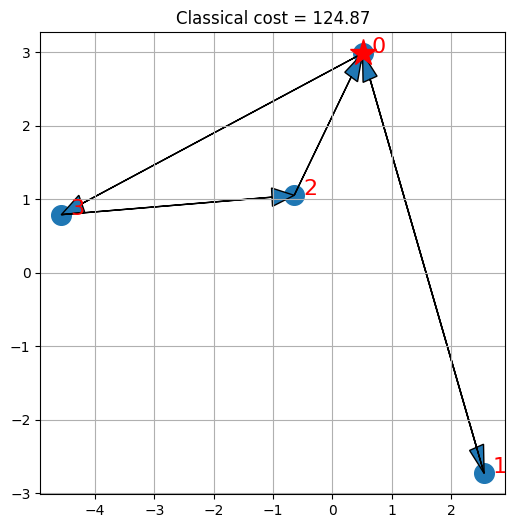

In [4]:
# ===== 3. Visualization function =====
def visualize_solution(xc, yc, x, C, n, K, title_str):
    plt.figure(figsize=(6,6))
    plt.scatter(xc, yc, s=200)
    for i in range(len(xc)):
        plt.annotate(i, (xc[i]+0.15, yc[i]), size=16, color='r')
    plt.plot(xc[0], yc[0], 'r*', ms=20)
    plt.grid()
    for ii in range(n**2):
        if x[ii] > 0:
            ix = ii//n; iy = ii%n
            plt.arrow(xc[ix], yc[ix], xc[iy]-xc[ix], yc[iy]-yc[ix], length_includes_head=True, head_width=0.25)
    plt.title(f"{title_str} cost = {C:.2f}")
    plt.show()

if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")


In [5]:
# ===== 4. Quantum optimizer =====
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE
from qiskit.algorithms.optimizers import SPSA
from qiskit.circuit.library import RealAmplitudes

class QuantumOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def binary_representation(self, x_sol=0):
        n, K, instance = self.n, self.K, self.instance
        A = np.max(instance)*100
        instance_vec = instance.reshape(n**2)
        w_list = [instance_vec[i] for i in range(n**2) if instance_vec[i]>0]
        w = np.zeros(n*(n-1))
        for i in range(len(w_list)):
            w[i] = w_list[i]

        Id_n = np.eye(n)
        Im_n_1 = np.ones([n-1, n-1])
        Iv_n_1 = np.ones(n); Iv_n_1[0] = 0
        Iv_n = np.ones(n-1)
        neg_Iv_n_1 = np.ones(n)-Iv_n_1
        v = np.zeros([n, n*(n-1)])
        for ii in range(n):
            count = ii-1
            for jj in range(n*(n-1)):
                if jj//(n-1) == ii: count=ii
                if jj//(n-1)!=ii and jj%(n-1)==count: v[ii,jj]=1.0
        vn = np.sum(v[1:], axis=0)
        Q = A*(np.kron(Id_n, Im_n_1)+np.dot(v.T,v))
        g = w - 2*A*(np.kron(Iv_n_1,Iv_n)+vn.T) - 2*A*K*(np.kron(neg_Iv_n_1,Iv_n)+v[0].T)
        c = 2*A*(n-1) + 2*A*K**2
        try:
            max(x_sol)
            cost = np.dot(np.around(x_sol), np.dot(Q, np.around(x_sol))) + np.dot(g,np.around(x_sol)) + c
        except:
            cost = 0
        return Q, g, c, cost

    def construct_problem(self, Q, g, c):
        qp = QuadraticProgram()
        for i in range(self.n*(self.n-1)):
            qp.binary_var(name=str(i))
        qp.objective.quadratic = Q
        qp.objective.linear = g
        qp.objective.constant = c
        return qp

    def solve_problem(self, qp):
        algorithm_globals.random_seed = 10598
        vqe_sampler = sampler if sampler is not None else None
        vqe = SamplingVQE(sampler=vqe_sampler, optimizer=SPSA(), ansatz=RealAmplitudes())
        optimizer = MinimumEigenOptimizer(min_eigen_solver=vqe)
        result = optimizer.solve(qp)
        _, _, _, level = self.binary_representation(result.x)
        return result.x, level


Binary cost: 124.87051695230184 Classical cost: 124.87051695229742
Binary formulation verified.
Quantum solution: [1. 1. 0. 1. 0. 0. 0. 0. 1. 1. 0. 0.]
Quantum cost: 124.87051695230184


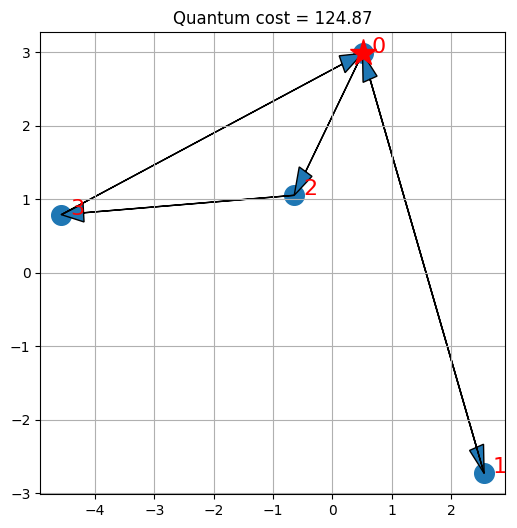

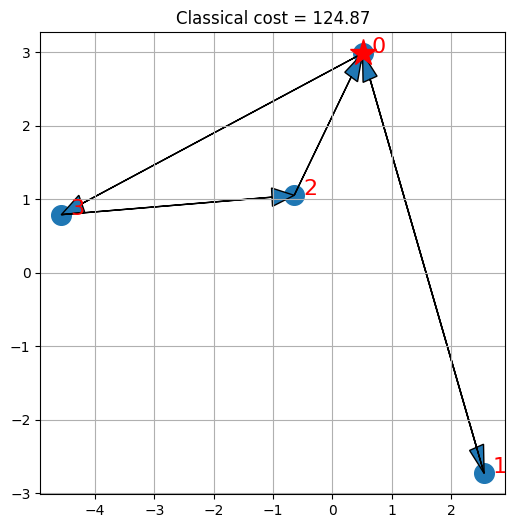

In [6]:
# ===== 5. Solve quantum problem and visualize =====
quantum_optimizer = QuantumOptimizer(instance, n, K)

# Verify binary formulation
if x is not None:
    Q, g, c, binary_cost = quantum_optimizer.binary_representation(z)
    print("Binary cost:", binary_cost, "Classical cost:", classical_cost)
    if abs(binary_cost-classical_cost)<0.01:
        print("Binary formulation verified.")
else:
    Q, g, c, binary_cost = quantum_optimizer.binary_representation()
    print("Binary cost:", binary_cost)

# Solve quantum problem
qp = quantum_optimizer.construct_problem(Q, g, c)
quantum_solution, quantum_cost = quantum_optimizer.solve_problem(qp)
print("Quantum solution:", quantum_solution)
print("Quantum cost:", quantum_cost)

# Map quantum solution to full x vector
x_quantum = np.zeros(n**2)
kk = 0
for ii in range(n**2):
    if ii//n != ii%n:
        x_quantum[ii] = quantum_solution[kk]
        kk += 1

# Visualize
visualize_solution(xc, yc, x_quantum, quantum_cost, n, K, "Quantum")
if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")
